In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import optuna
import optuna
import torch
import torch.nn as nn
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap
import seaborn as sns

RANDOM_STATE = 141026

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Device:", DEVICE)


Device: mps


## Part XIX — Hometask: VGG3D embeddings and cell-type classification

Use the alternative VGG3D representation of the same microscopy experiment:

```text
week6/large_object_vgg3d_embeddings_processed.csv
```

The target is `cell_type` with classes `m0`, `m1`, and `m2`. Do not use `sample_group` as a predictive feature; use it only to create leakage-safe partitions.

## Instructions

1. Inspect the table and complete a short preparation checklist: shape, data types, class balance, missingness, duplicate rows, feature ranges, and the meaning of `sample_group`.
2. Perform exploratory analysis with feature distributions and a PCA plus t-SNE or UMAP plot coloured by `cell_type`. Treat these projections as exploratory, not as test-set evaluation.
3. Create group-aware train, validation, and test partitions. Fit imputation and scaling on the training partition only, and verify that no `sample_group` occurs in more than one partition.
4. Train a multinomial logistic-regression baseline and a PyTorch MLP. Report learning curves, balanced accuracy, macro-F1, and a confusion matrix.
5. Run controlled MLP experiments: at least three learning rates, two network capacities, and two regularisation settings involving weight decay, dropout, or early stopping. Keep the split and random seed fixed.
6. Select the final model using validation data, evaluate it once on the untouched test set, and explain the errors biologically and statistically.

## Questions for the report

1. What does the VGG3D embedding table contain, and what data-preparation problems did you find?
2. Does the embedding space show separation between `m0`, `m1`, and `m2`? Is the separation also visible across sample groups?
3. How much does the MLP improve over logistic regression, and what evidence supports the comparison?
4. Which learning rate, capacity, and regularisation setting worked best? Did the MLP overfit?
5. Which cell types are confused most often, and do the errors concentrate in particular sample groups?
6. What biological or technical information is missing that could help explain the remaining errors?

## Deliverables

- completed notebook;
- preparation and leakage checks;
- PCA and t-SNE/UMAP visualisations;
- model comparison and learning-curve figures;
- final confusion matrix and six-question report.


### Step 1 Biological data-preparation checklist

In [2]:
data = pd.read_csv("large_object_vgg3d_embeddings_processed.csv")

In [3]:
print("Shape:", data.shape)
display(data.head())
display(data.dtypes.value_counts())

Shape: (381, 130)


,cell_type,sample_group,vgg_emb_000,vgg_emb_001,vgg_emb_002,vgg_emb_003,vgg_emb_004,vgg_emb_005,vgg_emb_006,vgg_emb_007,...,vgg_emb_118,vgg_emb_119,vgg_emb_120,vgg_emb_121,vgg_emb_122,vgg_emb_123,vgg_emb_124,vgg_emb_125,vgg_emb_126,vgg_emb_127
0,m0,sample_group_079,0.039772,0.0,1.179048,0.0,0.0,0.0,1.221995,0.0,...,0.0,0.0,0.0,0.797191,1.709197,0.0,0.777199,0.0,1.924863,0.0
1,m0,sample_group_079,0.000000,0.0,4.433527,0.0,0.0,0.0,5.810353,0.0,...,0.0,0.0,0.0,3.935624,6.289729,0.0,2.987612,0.0,8.424339,0.0
2,m0,sample_group_079,0.000000,0.0,4.108049,0.0,0.0,0.0,5.343654,0.0,...,0.0,0.0,0.0,3.621442,5.779456,0.0,2.740911,0.0,7.669261,0.0
3,m0,sample_group_079,0.000000,0.0,4.042331,0.0,0.0,0.0,5.283560,0.0,...,0.0,0.0,0.0,3.587561,5.783239,0.0,2.660382,0.0,7.480461,0.0
4,m0,sample_group_079,0.000000,0.0,2.474535,0.0,0.0,0.0,3.063431,0.0,...,0.0,0.0,0.0,2.021839,3.586300,0.0,1.637182,0.0,4.486126,0.0


float64    128
object       2
Name: count, dtype: int64

В оригінальному датасеті 381 зрізків та 130 фічей. cell_type це наш таргет, sample_group це технічна змінна по якій потім буде робитись розбивка.

In [4]:
display(pd.Series(data.columns, name="column"))


display(data.dtypes.rename("dtype").to_frame())


display(data.isna().sum().sort_values(ascending=False).head(15).rename("missing").to_frame())


for column in ["cell_type", "sample_group"]:
    print(f"{column}: {data[column].nunique()} unique values")
    display(data[column].value_counts(dropna=False).rename("count").to_frame())

0         cell_type
1      sample_group
2       vgg_emb_000
3       vgg_emb_001
4       vgg_emb_002
           ...     
125     vgg_emb_123
126     vgg_emb_124
127     vgg_emb_125
128     vgg_emb_126
129     vgg_emb_127
Name: column, Length: 130, dtype: object

,dtype
cell_type,object
sample_group,object
vgg_emb_000,float64
vgg_emb_001,float64
vgg_emb_002,float64
...,...
vgg_emb_123,float64
vgg_emb_124,float64
vgg_emb_125,float64
vgg_emb_126,float64


,missing
cell_type,0
vgg_emb_095,0
vgg_emb_093,0
vgg_emb_092,0
vgg_emb_091,0
vgg_emb_090,0
vgg_emb_089,0
vgg_emb_088,0
vgg_emb_087,0
vgg_emb_086,0


cell_type: 3 unique values


,count
cell_type,
m2,145
m0,132
m1,104


sample_group: 85 unique values


,count
sample_group,
sample_group_053,22
sample_group_021,22
sample_group_049,14
sample_group_079,13
sample_group_081,13
...,...
sample_group_070,1
sample_group_067,1
sample_group_083,1


У нас немає пропущених значень. В цілому класи збалансовані, хоча m2 трохи переважає. Ну і також ми бачимо що в одному sample_group у нас можу бути багато зразків які належать до одного того самого cell_type. Тобто вони не незалежні між собою і мають якісь спільні характеристики, тому при розбитті на тренувальну, валідаціну та тестову вибірки потрібно впевнитись що зразки з одного sample_group попадають тільки у train або test вибірку задля уникнення data leakage.

In [5]:
data[data['sample_group'] == 'sample_group_053']

,cell_type,sample_group,vgg_emb_000,vgg_emb_001,vgg_emb_002,vgg_emb_003,vgg_emb_004,vgg_emb_005,vgg_emb_006,vgg_emb_007,...,vgg_emb_118,vgg_emb_119,vgg_emb_120,vgg_emb_121,vgg_emb_122,vgg_emb_123,vgg_emb_124,vgg_emb_125,vgg_emb_126,vgg_emb_127
27,m0,sample_group_053,0.140439,0.0,0.527765,0.0,0.0,0.000000,0.353067,0.0,...,0.0,0.0,0.0,0.197052,0.741620,0.0,0.358325,0.0,0.759840,0.000000
28,m0,sample_group_053,0.000000,0.0,2.418229,0.0,0.0,0.000000,2.869986,0.0,...,0.0,0.0,0.0,2.018325,3.322415,0.0,1.596516,0.0,4.398501,0.000000
29,m0,sample_group_053,0.027768,0.0,1.324725,0.0,0.0,0.000000,1.375995,0.0,...,0.0,0.0,0.0,0.924921,1.811186,0.0,0.858429,0.0,2.195246,0.000000
30,m0,sample_group_053,0.060721,0.0,0.990938,0.0,0.0,0.000000,0.958275,0.0,...,0.0,0.0,0.0,0.656851,1.396532,0.0,0.659004,0.0,1.671494,0.000000
31,m0,sample_group_053,0.023418,0.0,1.327282,0.0,0.0,0.000000,1.390127,0.0,...,0.0,0.0,0.0,0.924306,1.819028,0.0,0.882782,0.0,2.241757,0.000000
32,m0,sample_group_053,0.173770,0.0,0.203540,0.0,0.0,0.062565,0.000000,0.0,...,0.0,0.0,0.0,0.000000,0.343091,0.0,0.169603,0.0,0.230325,0.107913
33,m0,sample_group_053,0.000000,0.0,2.055653,0.0,0.0,0.000000,2.376644,0.0,...,0.0,0.0,0.0,1.718905,2.843374,0.0,1.352349,0.0,3.738267,0.000000
34,m0,sample_group_053,0.000000,0.0,1.719870,0.0,0.0,0.000000,1.950984,0.0,...,0.0,0.0,0.0,1.320292,2.419391,0.0,1.156518,0.0,3.022341,0.000000
35,m0,sample_group_053,0.170659,0.0,0.187081,0.0,0.0,0.078273,0.000000,0.0,...,0.0,0.0,0.0,0.000000,0.269723,0.0,0.147562,0.0,0.136789,0.151274
36,m0,sample_group_053,0.000000,0.0,1.803920,0.0,0.0,0.000000,2.010316,0.0,...,0.0,0.0,0.0,1.435242,2.495636,0.0,1.176479,0.0,3.158603,0.000000


In [6]:
summary = data.describe().T
summary

,count,mean,std,min,25%,50%,75%,max
vgg_emb_000,381.0,0.009492,0.034612,0.000000,0.000000,0.000000,0.000000,0.183263
vgg_emb_001,381.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
vgg_emb_002,381.0,4.253172,2.794121,0.000000,2.205972,3.645934,5.784087,17.109690
vgg_emb_003,381.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
vgg_emb_004,381.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...
vgg_emb_123,381.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
vgg_emb_124,381.0,2.833346,1.868895,0.094944,1.453587,2.417135,3.866113,11.759638
vgg_emb_125,381.0,0.000031,0.000310,0.000000,0.000000,0.000000,0.000000,0.003633
vgg_emb_126,381.0,8.065610,5.587925,0.136789,3.953052,6.817931,11.175075,34.557022


З першого погляду не бачу ніяких проблем з feature ranges.

In [7]:
# Variance for all numerical features
variances = data.select_dtypes(include="number").var()

In [8]:
summary["variance"] = variances

summary[summary['variance'] == 0]

,count,mean,std,min,25%,50%,75%,max,variance
vgg_emb_001,381.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
vgg_emb_003,381.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
vgg_emb_004,381.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
vgg_emb_007,381.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
vgg_emb_014,381.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
vgg_emb_015,381.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
vgg_emb_017,381.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
vgg_emb_018,381.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
vgg_emb_019,381.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
vgg_emb_027,381.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


У нас є досить багато фіч з нульовою дисперсією, які по суті не несуть ніякої інформації про наш датасет, тому я думаю їх варто виключити.

In [9]:
candidate_features = summary.index[summary["variance"] > 0].tolist()

print("Candidate numerical features:", len(candidate_features))
print(candidate_features[:10])

Candidate numerical features: 91
['vgg_emb_000', 'vgg_emb_002', 'vgg_emb_005', 'vgg_emb_006', 'vgg_emb_008', 'vgg_emb_009', 'vgg_emb_010', 'vgg_emb_011', 'vgg_emb_012', 'vgg_emb_013']


In [10]:
print("Exact duplicate rows", int(data.duplicated().sum()))

Exact duplicate rows 0


У нас немає повноцінних дублікатів.

### Step 2 Exploratory data analysis: PCA, t-SNE, UMAP

/Users/elizavetafisun/Documents/ML_Bio/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


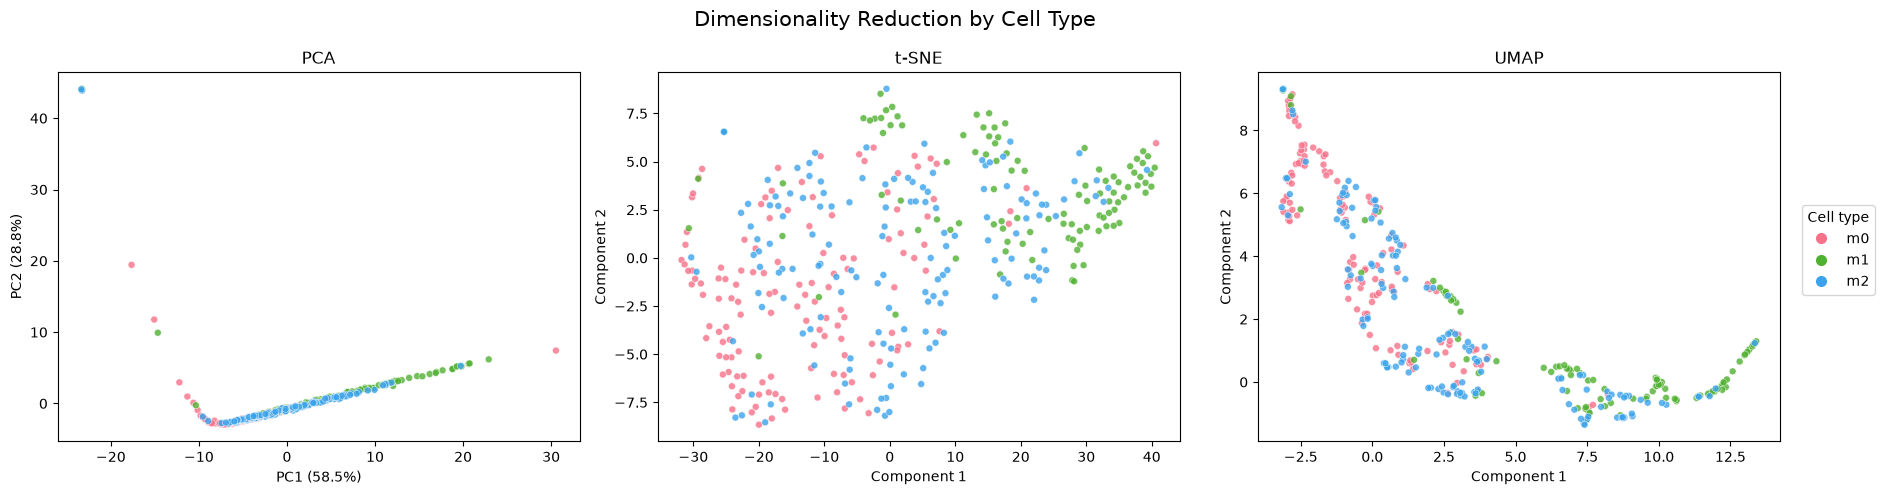

In [11]:
X = data[candidate_features]
y = data['cell_type']

scaler = StandardScaler()
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

tsne = TSNE(
    n_components=2,
    perplexity=min(30, (len(X_scaled) - 1) / 3),
    random_state=42,
    init="pca",
    learning_rate="auto"
)
X_tsne = tsne.fit_transform(X_scaled)

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=min(15, len(X_scaled) - 1),
    min_dist=0.1,
    random_state=42
)
X_umap = umap_model.fit_transform(X_scaled)


embeddings = {
    "PCA": X_pca,
    "t-SNE": X_tsne,
    "UMAP": X_umap
}

cell_types = y.unique()
palette = dict(zip(
    cell_types,
    sns.color_palette("husl", len(cell_types))
))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, embedding) in zip(axes, embeddings.items()):
    plot_df = pd.DataFrame({
        "Dim 1": embedding[:, 0],
        "Dim 2": embedding[:, 1],
        "cell_type": y.to_numpy()
    })

    sns.scatterplot(
        data=plot_df,
        x="Dim 1",
        y="Dim 2",
        hue="cell_type",
        palette=palette,
        s=25,
        alpha=0.8,
        ax=ax,
        legend=False
    )

    ax.set_title(name)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")

    if name == "PCA":
        ax.set_xlabel(
            f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"
        )
        ax.set_ylabel(
            f"PC2 ({pca.explained_variance_ratio_[1]:.1%})"
        )

# Shared legend
handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        color=palette[cell_type],
        label=str(cell_type),
        markersize=7
    )
    for cell_type in cell_types
]

fig.legend(
    handles=handles,
    title="Cell type",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5)
)

plt.suptitle("Dimensionality Reduction by Cell Type", fontsize=15)
plt.tight_layout()
plt.show()

Не спостерігаємо чіткого розділення на кластери.

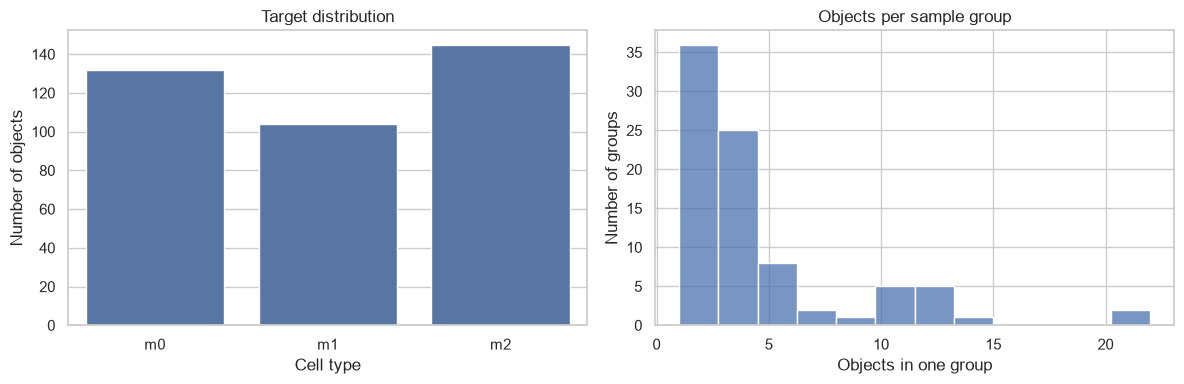

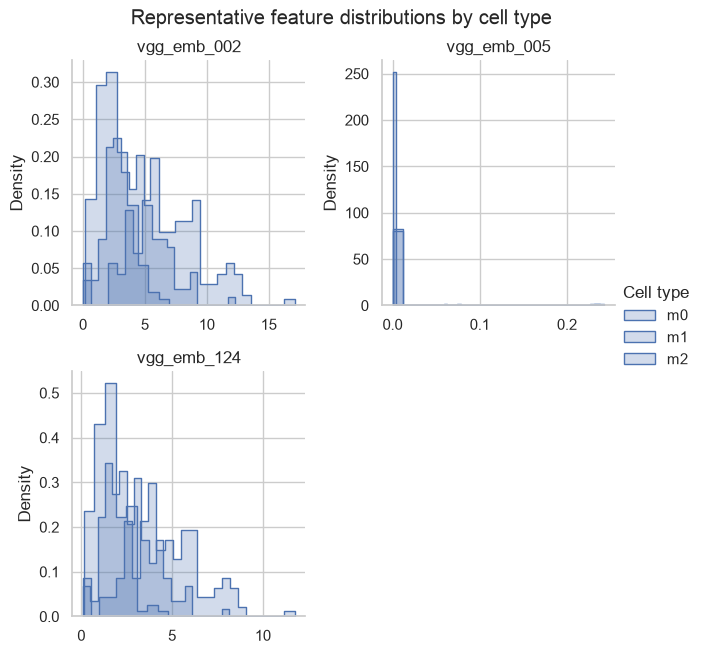

In [16]:
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

plot_features = [
    column for column in [
        'vgg_emb_002', 'vgg_emb_005', 'vgg_emb_124'
    ]
    if column in data.columns
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=data,
    x="cell_type",
    order=["m0", "m1", "m2"],
    ax=axes[0],
)
axes[0].set_title("Target distribution")
axes[0].set_xlabel("Cell type")
axes[0].set_ylabel("Number of objects")

group_sizes = data["sample_group"].value_counts()
sns.histplot(group_sizes, bins=12, ax=axes[1])
axes[1].set_title("Objects per sample group")
axes[1].set_xlabel("Objects in one group")
axes[1].set_ylabel("Number of groups")

plt.tight_layout()
plt.show()

if plot_features:
    long_features = data.melt(
        id_vars=["cell_type"],
        value_vars=plot_features,
        var_name="feature",
        value_name="value",
    )
    g = sns.FacetGrid(
        long_features,
        col="feature",
        col_wrap=2,
        hue="cell_type",
        sharex=False,
        sharey=False,
        height=3.2,
    )
    g.map_dataframe(
        sns.histplot,
        bins=20,
        element="step",
        stat="density",
        common_norm=False,
    )
    g.add_legend(title="Cell type")
    g.set_titles("{col_name}")
    g.fig.suptitle("Representative feature distributions by cell type", y=1.02)
    plt.show()

vgg_emb_05 можливо не дуже інформативна так як у нас всі три класти розатошовані навколо нуля

### Step 3 Group-aware split

In [13]:

groups = data['sample_group'].copy()

In [14]:
def split_quality(test_indices, y_values, target_fraction):
    overall_proportions = y_values.value_counts(normalize=True).sort_index()
    test_proportions = (
        y_values.iloc[test_indices]
        .value_counts(normalize=True)
        .reindex(overall_proportions.index)
        .fillna(0)
    )
    size_error = abs(len(test_indices) / len(y_values) - target_fraction)
    class_error = np.abs(test_proportions - overall_proportions).sum()
    return size_error + class_error


outer_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)
outer_splits = list(outer_splitter.split(X, y, groups=groups))

outer_fold_index = min(
    range(len(outer_splits)),
    key=lambda index: split_quality(
        outer_splits[index][1],
        y,
        target_fraction=0.20,
    ),
)
train_idx, test_idx = outer_splits[outer_fold_index]

X_train_full = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train_full = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_train_full = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

shared_groups = set(groups_train_full).intersection(groups_test)

print("Selected outer fold:", outer_fold_index)
print("Training objects:", len(X_train_full))
print("Test objects:", len(X_test))
print("Training groups:", groups_train_full.nunique())
print("Test groups:", groups_test.nunique())
print("Shared groups:", len(shared_groups))
print("Overall class proportions:")
print(y.value_counts(normalize=True).sort_index())
print("Test class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

assert len(shared_groups) == 0
assert set(y_test.unique()) == set(y.unique())

Selected outer fold: 3
Training objects: 305
Test objects: 76
Training groups: 68
Test groups: 17
Shared groups: 0
Overall class proportions:
cell_type
m0    0.346457
m1    0.272966
m2    0.380577
Name: proportion, dtype: float64
Test class proportions:
cell_type
m0    0.342105
m1    0.276316
m2    0.381579
Name: proportion, dtype: float64


In [15]:
inner_splitter = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE + 1,
)
inner_splits = list(
    inner_splitter.split(
        X_train_full,
        y_train_full,
        groups=groups_train_full,
    )
)

inner_fold_index = min(
    range(len(inner_splits)),
    key=lambda index: split_quality(
        inner_splits[index][1],
        y_train_full,
        target_fraction=0.25,
    ),
)
train_idx2, val_idx = inner_splits[inner_fold_index]

X_train = X_train_full.iloc[train_idx2].copy()
X_val = X_train_full.iloc[val_idx].copy()
y_train = y_train_full.iloc[train_idx2].copy()
y_val = y_train_full.iloc[val_idx].copy()
groups_train = groups_train_full.iloc[train_idx2].copy()
groups_val = groups_train_full.iloc[val_idx].copy()

shared_train_val_groups = set(groups_train).intersection(groups_val)

print("Selected inner fold:", inner_fold_index)
print("Training objects:", len(X_train))
print("Validation objects:", len(X_val))
print("Training groups:", groups_train.nunique())
print("Validation groups:", groups_val.nunique())
print("Shared train/validation groups:", len(shared_train_val_groups))
print("Training class proportions:")
print(y_train.value_counts(normalize=True).sort_index())
print("Validation class proportions:")
print(y_val.value_counts(normalize=True).sort_index())

assert len(shared_train_val_groups) == 0
assert set(y_val.unique()) == set(y.unique())

Selected inner fold: 2
Training objects: 230
Validation objects: 75
Training groups: 51
Validation groups: 17
Shared train/validation groups: 0
Training class proportions:
cell_type
m0    0.347826
m1    0.269565
m2    0.382609
Name: proportion, dtype: float64
Validation class proportions:
cell_type
m0    0.346667
m1    0.280000
m2    0.373333
Name: proportion, dtype: float64


In [20]:
train_groups = set(groups_train_full.iloc[train_idx2])
val_groups = set(groups_train_full.iloc[val_idx])
test_groups = set(groups.iloc[test_idx])

assert train_groups.isdisjoint(val_groups), "Train/Val leakage!"
assert train_groups.isdisjoint(test_groups), "Train/Test leakage!"
assert val_groups.isdisjoint(test_groups), "Val/Test leakage!"

print("No sample_group overlap between partitions!")

No sample_group overlap between partitions!


In [21]:
from sklearn.pipeline import Pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Fit ONLY on training data
X_train_scaled = preprocessor.fit_transform(X_train)

# Apply the SAME transformations to validation and test
X_val_scaled = preprocessor.transform(X_val)
X_test_scaled = preprocessor.transform(X_test)

### Step 4 Multinomial logistic-regression baseline and a PyTorch MLP

In [22]:
from sklearn.preprocessing import LabelEncoder
# Encode target labels: m0, m1, m2 -> 0, 1, 2
encoder = LabelEncoder()

y_train_enc = encoder.fit_transform(y_train)
y_val_enc = encoder.transform(y_val)
y_test_enc = encoder.transform(y_test)

n_classes = len(encoder.classes_)
n_features = X_train_scaled.shape[1]

print("Classes:", encoder.classes_)
print("Number of features:", n_features)

Classes: ['m0' 'm1' 'm2']
Number of features: 91


In [36]:
from sklearn.metrics import confusion_matrix

def evaluate_model(model_name, split, y_true, y_pred, y_proba):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(n_classes)
    )
    confusion_matrices[(model_name, split)] = cm
    return {
        "model": model_name,
        "split": split,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

results = []
confusion_matrices = {}

In [37]:
logreg = LogisticRegression(
    solver="lbfgs",
    max_iter=2000,
    C=1.0,
    random_state=RANDOM_STATE
)

logreg.fit(X_train_scaled, y_train_enc)

for split_name, X_split, y_split in [
    ("train", X_train_scaled, y_train_enc),
    ("validation", X_val_scaled, y_val_enc),
    ("test", X_test_scaled, y_test_enc)
]:
    y_pred = logreg.predict(X_split)
    y_proba = logreg.predict_proba(X_split)

    results.append(
        evaluate_model(
            "Logistic Regression",
            split_name,
            y_split,
            y_pred,
            y_proba
        )
    )

In [38]:
display(pd.DataFrame(results).round(4))

,model,split,accuracy,balanced_accuracy,f1_macro
0,Logistic Regression,train,0.7391,0.7409,0.7469
1,Logistic Regression,validation,0.6533,0.6603,0.6705
2,Logistic Regression,test,0.6053,0.6341,0.6132


In [39]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

class_names = sorted(y.unique())
class_to_index = {name: index for index, name in enumerate(class_names)}

y_train_t = torch.tensor(
    y_train.map(class_to_index).to_numpy(),
    dtype=torch.long,
)
y_val_t = torch.tensor(
    y_val.map(class_to_index).to_numpy(),
    dtype=torch.long,
)
y_test_t = torch.tensor(
    y_test.map(class_to_index).to_numpy(),
    dtype=torch.long,
)

print("Class mapping:", class_to_index)
print("Training tensor shapes:", X_train_t.shape, y_train_t.shape)
print("Validation tensor shapes:", X_val_t.shape, y_val_t.shape)
print("Test tensor shapes:", X_test_t.shape, y_test_t.shape)

Class mapping: {'m0': 0, 'm1': 1, 'm2': 2}
Training tensor shapes: torch.Size([230, 91]) torch.Size([230])
Validation tensor shapes: torch.Size([75, 91]) torch.Size([75])
Test tensor shapes: torch.Size([76, 91]) torch.Size([76])


In [40]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 32

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 8
Validation batches: 3
Test batches: 3


In [41]:
class MLP(nn.Module):
    def __init__(self, input_dim, n_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, n_classes)
        )

    def forward(self, x):
        return self.network(x)


In [42]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

        pred = logits.argmax(dim=1)

        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


In [53]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_preds = []
    all_targets = []
    all_probs = []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        total_loss += loss.item() * X_batch.size(0)
        total_samples += X_batch.size(0)

        preds = logits.argmax(dim=1)
        probs = torch.softmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y_batch.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

    y_true = np.array(all_targets)
    y_pred = np.array(all_preds)
    y_proba = np.array(all_probs)

    n_classes = y_proba.shape[1]

    metrics = {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }
    cm = confusion_matrix(
            y_true,
            y_pred,
            labels=np.arange(n_classes)
        )
    confusion_matrices[(model_name, split)] = cm

    return metrics

In [44]:
input_dim = X_train_scaled.shape[1]
n_classes = len(class_names)

model = MLP(
    input_dim=input_dim,
    n_classes=n_classes,
).to(DEVICE)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=91, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)


In [45]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [46]:
criterion = nn.CrossEntropyLoss()

with torch.no_grad():
    logits = model(X_train_t[:5].to(DEVICE))
    probabilities = torch.softmax(logits, dim=1)

print("Logits shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)
print("Probabilities:")
display(probabilities.cpu().numpy())
print("Probability sums:", probabilities.sum(dim=1).cpu().numpy())

Logits shape: torch.Size([5, 3])
Probabilities shape: torch.Size([5, 3])
Probabilities:


array([[0.35869536, 0.31717348, 0.3241312 ],
       [0.3119886 , 0.36448047, 0.32353106],
       [0.311675  , 0.3637357 , 0.32458922],
       [0.3120551 , 0.3647608 , 0.32318413],
       [0.3370251 , 0.33958477, 0.32339022]], dtype=float32)

Probability sums: [1.        1.0000001 1.        1.        1.0000001]


In [60]:
N_EPOCHS = 100

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(N_EPOCHS):
     train_loss, train_acc = train_one_epoch(
         model,
         train_loader,
         criterion,
         optimizer,
         DEVICE)

     train_metrics = evaluate(model, train_loader, criterion, DEVICE)
     val_metrics = evaluate(model, val_loader, criterion, DEVICE)
     test_metrics = evaluate(model, test_loader, criterion, DEVICE)

     history["train_loss"].append(train_loss)
     history["val_loss"].append(val_metrics['loss'])
     history["train_acc"].append(train_acc)
     history["val_acc"].append(val_metrics['accuracy'])

     if (epoch + 1) % 5 == 0:
         print(
             f"Epoch {epoch+1:03d} | "
             f"train loss={train_loss:.4f} | "
             f"val loss={val_metrics['loss']:.4f} | "
             f"train acc={train_acc:.3f} | "
             f"val acc={val_metrics['accuracy']:.3f}")


Epoch 005 | train loss=0.3989 | val loss=1.1378 | train acc=0.826 | val acc=0.640
Epoch 010 | train loss=0.4061 | val loss=1.1434 | train acc=0.813 | val acc=0.653
Epoch 015 | train loss=0.3991 | val loss=1.2005 | train acc=0.813 | val acc=0.627
Epoch 020 | train loss=0.3936 | val loss=1.1643 | train acc=0.826 | val acc=0.640
Epoch 025 | train loss=0.3870 | val loss=1.1325 | train acc=0.835 | val acc=0.640
Epoch 030 | train loss=0.3910 | val loss=1.1772 | train acc=0.843 | val acc=0.640
Epoch 035 | train loss=0.3849 | val loss=1.1917 | train acc=0.822 | val acc=0.653
Epoch 040 | train loss=0.3881 | val loss=1.1625 | train acc=0.809 | val acc=0.653
Epoch 045 | train loss=0.3896 | val loss=1.1612 | train acc=0.839 | val acc=0.667
Epoch 050 | train loss=0.3768 | val loss=1.1537 | train acc=0.839 | val acc=0.640
Epoch 055 | train loss=0.3746 | val loss=1.1891 | train acc=0.848 | val acc=0.653
Epoch 060 | train loss=0.3853 | val loss=1.2127 | train acc=0.830 | val acc=0.653
Epoch 065 | trai

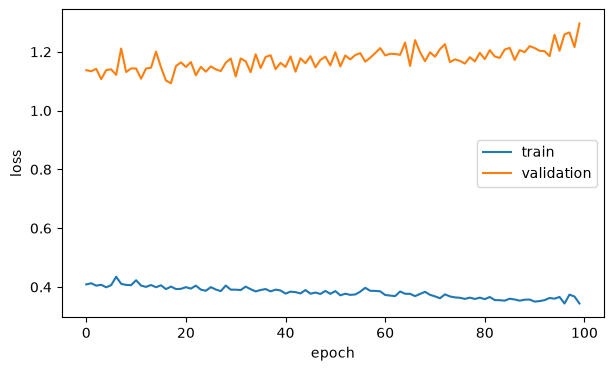

In [61]:
plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()


In [62]:
confusion_matrices

{('Logistic Regression',
  'train'): array([[63,  0, 17],
        [ 3, 46, 13],
        [20,  7, 61]]),
 ('Logistic Regression',
  'validation'): array([[19,  1,  6],
        [ 0, 15,  6],
        [13,  0, 15]]),
 ('Logistic Regression',
  'test'): array([[20,  0,  6],
        [ 1, 18,  2],
        [19,  2,  8]]),
 ('PyTorch MLP',
  'test'): array([[17,  0,  9],
        [ 1, 14,  6],
        [18,  2,  9]])}

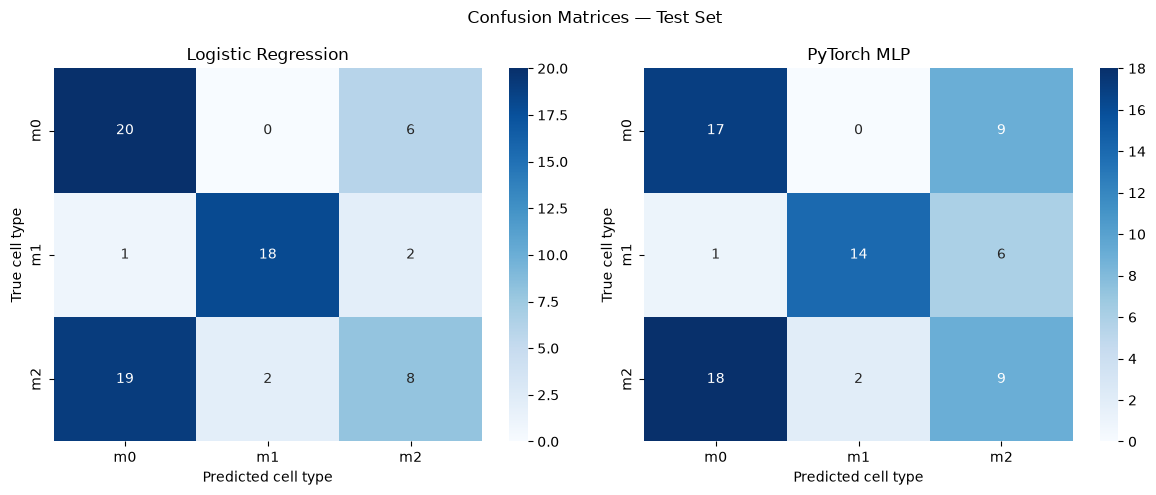

In [63]:
models = ["Logistic Regression", "PyTorch MLP"]
split = "test"

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model_name in zip(axes, models):
    cm = confusion_matrices[(model_name, split)]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=encoder.classes_,
        yticklabels=encoder.classes_,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted cell type")
    ax.set_ylabel("True cell type")

plt.suptitle("Confusion Matrices — Test Set")
plt.tight_layout()
plt.show()

### Step 5 Run MLP experiments

In [74]:

class FlexibleMLP(nn.Module):
    def __init__(self, input_dim, n_classes, hidden_dims=(32, 16)):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.ReLU()
            ])
            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


In [75]:

@torch.no_grad()
def evaluate_experiment(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_samples = 0
    all_preds = []
    all_targets = []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        total_loss += loss.item() * X_batch.size(0)
        total_samples += X_batch.size(0)

        all_preds.extend(logits.argmax(dim=1).cpu().numpy())
        all_targets.extend(y_batch.cpu().numpy())

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(all_targets, all_preds),
        "f1_macro": f1_score(
            all_targets, all_preds,
            average="macro", zero_division=0
        )
    }


def run_experiment(
    lr,
    hidden_dims,
    weight_decay,
    n_epochs=100,
    patience=15
):
    # Same seed for every experiment
    random.seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)
    torch.manual_seed(RANDOM_STATE)

    # Recreate shuffled batches deterministically
    generator = torch.Generator().manual_seed(RANDOM_STATE)

    experiment_train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    model = FlexibleMLP(
        input_dim=n_features,
        n_classes=n_classes,
        hidden_dims=hidden_dims
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(n_epochs):
        train_loss, train_acc = train_one_epoch(
            model,
            experiment_train_loader,
            criterion,
            optimizer,
            DEVICE
        )

        val_metrics = evaluate_experiment(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_metrics["accuracy"])

        # Early stopping based on validation loss
        if val_metrics["loss"] < best_val_loss - 1e-5:
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    # Restore the best model
    model.load_state_dict(best_state)

    train_metrics = evaluate_experiment(
        model, train_loader, criterion
    )
    val_metrics = evaluate_experiment(
        model, val_loader, criterion
    )

    result = {
        "lr": lr,
        "hidden_dims": str(hidden_dims),
        "weight_decay": weight_decay,
        "best_epoch": best_epoch,
        "epochs_trained": len(history["train_loss"]),
        "train_accuracy": train_metrics["accuracy"],
        "val_accuracy": val_metrics["accuracy"],
        "val_f1_macro": val_metrics["f1_macro"],
        "val_loss": val_metrics["loss"]
    }

    return result, history, model


In [76]:

from itertools import product

learning_rates = [1e-4, 1e-3, 1e-2]
hidden_dims_options = [(32, 16), (64, 32)]
weight_decays = [0.0, 1e-3]

experiment_results = []
experiment_histories = {}
experiment_models = {}

configs = list(product(
    learning_rates,
    hidden_dims_options,
    weight_decays
))

for i, (lr, hidden_dims, wd) in enumerate(configs, start=1):
    experiment_id = f"exp_{i:02d}"

    print(
        f"[{i}/{len(configs)}] "
        f"lr={lr}, hidden_dims={hidden_dims}, "
        f"weight_decay={wd}"
    )

    result, exp_history, exp_model = run_experiment(
        lr=lr,
        hidden_dims=hidden_dims,
        weight_decay=wd
    )

    result["experiment_id"] = experiment_id

    experiment_results.append(result)
    experiment_histories[experiment_id] = exp_history
    experiment_models[experiment_id] = exp_model

# Results table
experiments_df = pd.DataFrame(experiment_results)

experiments_df = experiments_df.sort_values(
    ["val_f1_macro", "val_loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(experiments_df.round(4))

# Save results locally
experiments_df.to_csv("mlp_experiments.csv", index=False)


[1/12] lr=0.0001, hidden_dims=(32, 16), weight_decay=0.0
[2/12] lr=0.0001, hidden_dims=(32, 16), weight_decay=0.001
[3/12] lr=0.0001, hidden_dims=(64, 32), weight_decay=0.0
[4/12] lr=0.0001, hidden_dims=(64, 32), weight_decay=0.001
[5/12] lr=0.001, hidden_dims=(32, 16), weight_decay=0.0
[6/12] lr=0.001, hidden_dims=(32, 16), weight_decay=0.001
[7/12] lr=0.001, hidden_dims=(64, 32), weight_decay=0.0
[8/12] lr=0.001, hidden_dims=(64, 32), weight_decay=0.001
[9/12] lr=0.01, hidden_dims=(32, 16), weight_decay=0.0
[10/12] lr=0.01, hidden_dims=(32, 16), weight_decay=0.001
[11/12] lr=0.01, hidden_dims=(64, 32), weight_decay=0.0
[12/12] lr=0.01, hidden_dims=(64, 32), weight_decay=0.001


,lr,hidden_dims,weight_decay,best_epoch,epochs_trained,train_accuracy,val_accuracy,val_f1_macro,val_loss,experiment_id
0,0.0100,"(64, 32)",0.000,17,32,0.6783,0.6400,0.6406,0.9847,exp_11
1,0.0100,"(32, 16)",0.001,10,25,0.6609,0.6133,0.6328,0.9276,exp_10
2,0.0100,"(32, 16)",0.000,19,34,0.6783,0.6267,0.6314,0.9442,exp_09
3,0.0100,"(64, 32)",0.001,4,19,0.6478,0.6000,0.6245,0.9665,exp_12
4,0.0001,"(64, 32)",0.000,36,51,0.6478,0.5733,0.5626,0.9380,exp_03
5,0.0001,"(64, 32)",0.001,35,50,0.6478,0.5733,0.5626,0.9498,exp_04
6,0.0010,"(32, 16)",0.001,6,21,0.6522,0.5600,0.5619,0.9806,exp_06
7,0.0001,"(32, 16)",0.001,54,69,0.6391,0.5467,0.5453,0.9665,exp_02
8,0.0001,"(32, 16)",0.000,54,69,0.6435,0.5467,0.5453,0.9671,exp_01
9,0.0010,"(32, 16)",0.000,6,21,0.6478,0.5467,0.5441,0.9804,exp_05


### Step 6 Test best model

In [78]:

best_result = experiments_df.iloc[0]
best_id = best_result["experiment_id"]

best_model = experiment_models[best_id]

print("Best experiment:", best_id)
display(best_result.to_frame("value"))

criterion = nn.CrossEntropyLoss()

test_metrics = evaluate_experiment(
    best_model,
    test_loader,
    criterion
)

print("\nFinal test performance:")
display(pd.DataFrame([test_metrics]).round(4))


Best experiment: exp_11


,value
lr,0.01
hidden_dims,"(64, 32)"
weight_decay,0.0
best_epoch,17
epochs_trained,32
train_accuracy,0.678261
val_accuracy,0.64
val_f1_macro,0.640554
val_loss,0.984686
experiment_id,exp_11



Final test performance:


,loss,accuracy,f1_macro
0,0.7333,0.6316,0.6122


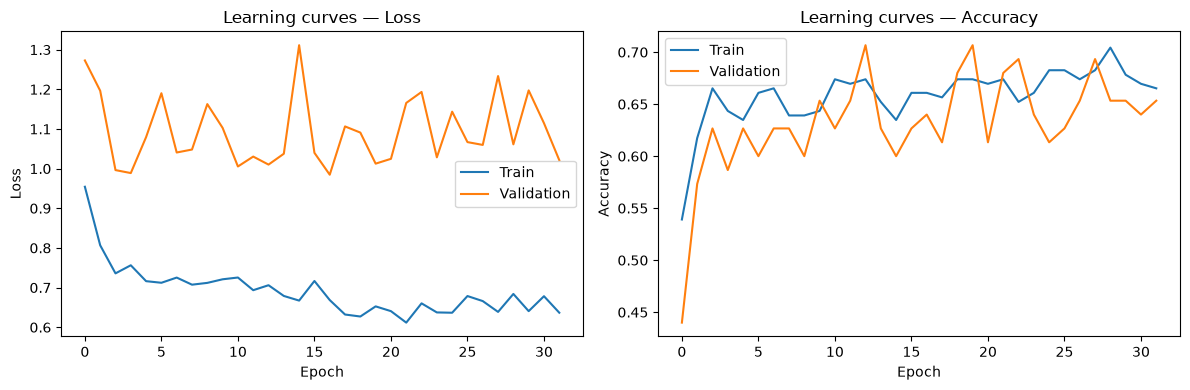

In [79]:

best_history = experiment_histories[best_id]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(best_history["train_loss"], label="Train")
axes[0].plot(best_history["val_loss"], label="Validation")
axes[0].set_title("Learning curves — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(best_history["train_acc"], label="Train")
axes[1].plot(best_history["val_acc"], label="Validation")
axes[1].set_title("Learning curves — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

          m0       0.52      0.88      0.66        26
          m1       0.83      0.90      0.86        21
          m2       0.67      0.21      0.32        29

    accuracy                           0.63        76
   macro avg       0.67      0.67      0.61        76
weighted avg       0.66      0.63      0.58        76



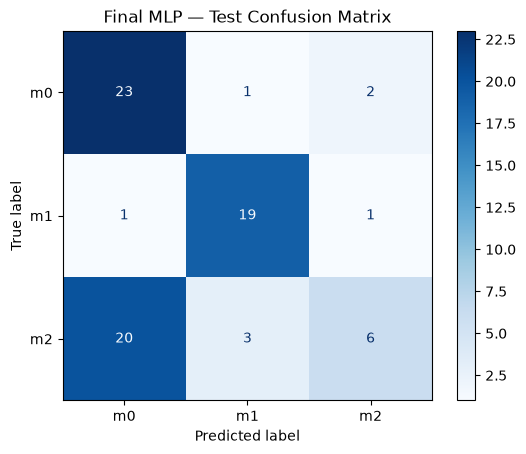

In [80]:

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

# Use the final model selected using validation data
best_model.eval()

with torch.no_grad():
    logits = best_model(X_test_t.to(DEVICE))
    y_pred = logits.argmax(dim=1).cpu().numpy()

y_true = y_test_t.cpu().numpy()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(cmap="Blues")

plt.title("Final MLP — Test Confusion Matrix")
plt.show()


m1 — найкраще розпізнаваний клас. Recall = 0.90, F1 = 0.86. Модель правильно класифікувала 19 із 21 зразка.  
m0 — високий recall, але низький precision. Модель правильно розпізнала 23 із 26 зразків, але часто помилково відносить інші класи до m0.  
m2 — основне джерело помилок. Recall = 0.21, тобто лише 6 із 29 зразків класифіковані правильно. Найчастіше m2 помилково визначається як m0 (20 випадків).  
Перша гіпотеза що класи m0 та m2 чимось схожі за морфологічними характеристиками

Independent groups per class:
cell_type
m0    11
m1    28
m2    12
Name: sample_group, dtype: int64


,m0,m1,m2
m0,0.000,9.160,3.903
m1,9.160,0.000,6.342
m2,3.903,6.342,0.000


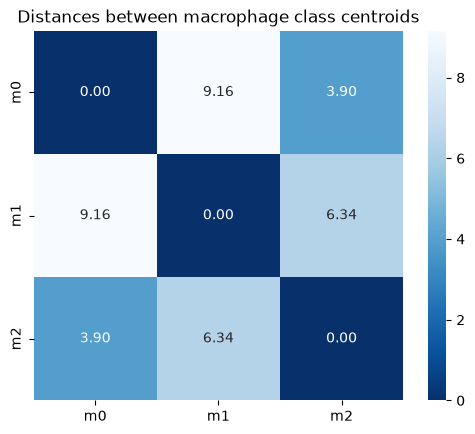

In [88]:

from scipy.spatial.distance import pdist, squareform

feature_names = list(X_train.columns)

analysis_df = pd.DataFrame(
    X_train_scaled,
    columns=feature_names,
    index=X_train.index
)

analysis_df["cell_type"] = y_train.to_numpy()
analysis_df["sample_group"] = groups_train.to_numpy()

# One mean embedding per sample group and cell type
group_df = (
    analysis_df
    .groupby(["sample_group", "cell_type"], as_index=False)[feature_names]
    .mean()
)

print("Independent groups per class:")
print(group_df.groupby("cell_type")["sample_group"].nunique())

# Mean embedding for each class
centroids = (
    group_df.groupby("cell_type")[feature_names]
    .mean()
    .reindex(classes)
)

assert not centroids.isna().any().any()

distances = squareform(
    pdist(centroids.to_numpy(), metric="euclidean")
)

distance_df = pd.DataFrame(
    distances,
    index=classes,
    columns=classes
)

display(distance_df.round(3))

sns.heatmap(
    distance_df,
    annot=True,
    fmt=".2f",
    cmap="Blues_r",
    square=True
)

plt.title("Distances between macrophage class centroids")
plt.show()


Бачимо що тут відстань між класами m0 та m2 найменша

In [85]:

from sklearn.metrics import silhouette_samples, silhouette_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Same features used in centroid distance analysis
feature_cols = [
    col for col in group_df.columns
    if col.startswith("vgg_emb_")
]

X_sil = group_df[feature_cols].to_numpy()
y_sil = group_df["cell_type"].to_numpy()

classes = ["m0", "m1", "m2"]

# Check class sizes
print("Number of groups per class:")
print(pd.Series(y_sil).value_counts())

assert len(np.unique(y_sil)) >= 2
assert len(np.unique(y_sil)) < len(y_sil)

# Silhouette for every group
sil_values = silhouette_samples(
    X_sil,
    y_sil,
    metric="euclidean"
)

sil_df = pd.DataFrame({
    "cell_type": y_sil,
    "silhouette": sil_values
})

# Overall silhouette
overall_silhouette = silhouette_score(
    X_sil,
    y_sil,
    metric="euclidean"
)

print(f"Overall silhouette score: {overall_silhouette:.3f}")

# Per-class statistics
sil_summary = (
    sil_df.groupby("cell_type")["silhouette"]
    .agg(["mean", "median", "std", "count"])
    .reindex(classes)
)

display(sil_summary.round(3))


Number of groups per class:
m1    28
m2    12
m0    11
Name: count, dtype: int64
Overall silhouette score: -0.009


,mean,median,std,count
cell_type,,,,
m0,0.484,0.554,0.170,11
m1,-0.051,0.098,0.343,28
m2,-0.361,-0.342,0.230,12


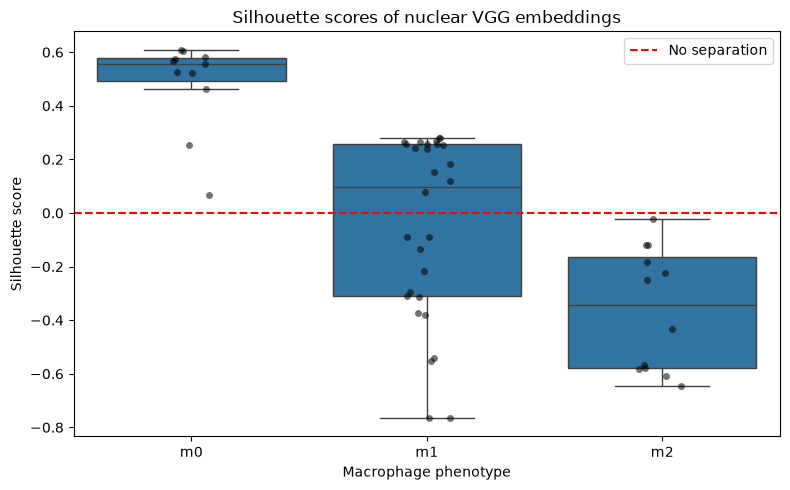

In [86]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=sil_df,
    x="cell_type",
    y="silhouette",
    order=classes,
    showfliers=False
)

sns.stripplot(
    data=sil_df,
    x="cell_type",
    y="silhouette",
    order=classes,
    color="black",
    alpha=0.55,
    size=5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="No separation"
)

plt.xlabel("Macrophage phenotype")
plt.ylabel("Silhouette score")
plt.title("Silhouette scores of nuclear VGG embeddings")
plt.legend()
plt.tight_layout()
plt.show()


У m2 найгірший silhouette_score

1. What does the VGG3D embedding table contain, and what data-preparation problems did you find?  
Різні морфологічні характеристики ядра макрофагів, треба враховувати sample_group при розбивці.  
2. Does the embedding space show separation between `m0`, `m1`, and `m2`? Is the separation also visible across sample groups?
Нсапрвді розділення не дуже видно. Розділення за sample_group теж особливо немає (PCA plot внизу). 
3. How much does the MLP improve over logistic regression, and what evidence supports the comparison?  
Покращення дуже мінімальне якщо дивитись на accuracy або f1-score: aroun 0.61. 
4. Which learning rate, capacity, and regularisation setting worked best? Did the MLP overfit?  
Best learning rate: 0.01
Best hidden dimensions: (64, 32)
Best weight decay: 0.0
Best epoch: 17
Train accuracy: 0.6782608695652174
Validation accuracy: 0.64
Validation macro F1: 0.6405542939548144
Після 17 епохи оверфітиться, але я би сказала що validation_loss загалом трохи стохастична.  
5. Which cell types are confused most often, and do the errors concentrate in particular sample groups?
Більше всього помилок у m2, так є певні smaple_groups де найбільше всього помилок, аналіз наведений внизу.  
6. What biological or technical information is missing that could help explain the remaining errors?
Мені здається якщо додати більш релевантні фічі це може допомогти краще розрізняти класи макрофагів. Або може спробувати зробити CNN та працювати з зображеннями.  

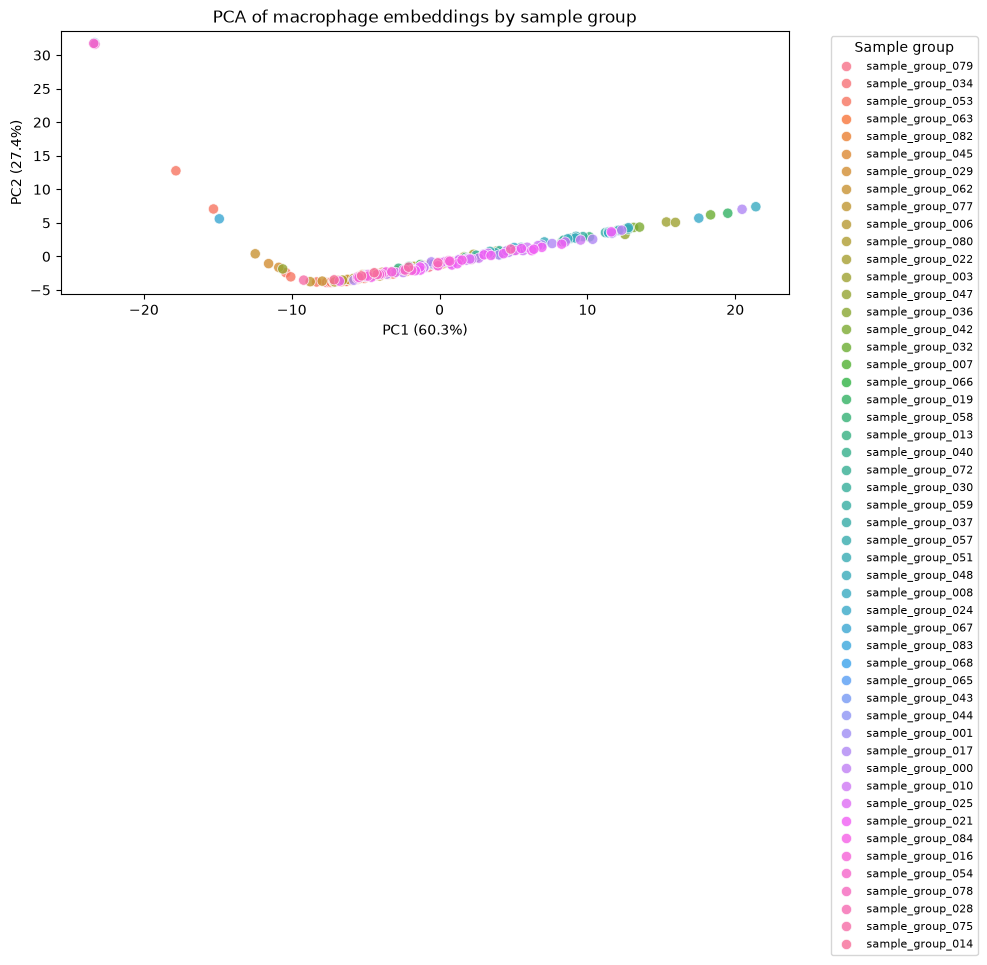

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Use existing training data
X_analysis = np.asarray(X_train_scaled)

# Labels and sample groups from the same training rows
y_analysis = y_train.to_numpy()
groups_analysis = groups_train.to_numpy()

assert len(X_analysis) == len(y_analysis) == len(groups_analysis)

# 2. Calculate PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_analysis)

# 3. Create DataFrame
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cell_type": y_analysis,
    "sample_group": groups_analysis
})

# 4. Visualize sample groups
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="sample_group",
    palette="husl",
    s=55,
    alpha=0.8
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("PCA of macrophage embeddings by sample group")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    title="Sample group",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [90]:

# Best configuration based on validation macro F1
best = experiments_df.sort_values(
    ["val_f1_macro", "val_loss"],
    ascending=[False, True]
).iloc[0]

print("Best learning rate:", best["lr"])
print("Best hidden dimensions:", best["hidden_dims"])
print("Best weight decay:", best["weight_decay"])
print("Best epoch:", best["best_epoch"])

print("Train accuracy:", best["train_accuracy"])
print("Validation accuracy:", best["val_accuracy"])
print("Validation macro F1:", best["val_f1_macro"])


Best learning rate: 0.01
Best hidden dimensions: (64, 32)
Best weight decay: 0.0
Best epoch: 17
Train accuracy: 0.6782608695652174
Validation accuracy: 0.64
Validation macro F1: 0.6405542939548144


Train-validation accuracy gap: 0.038


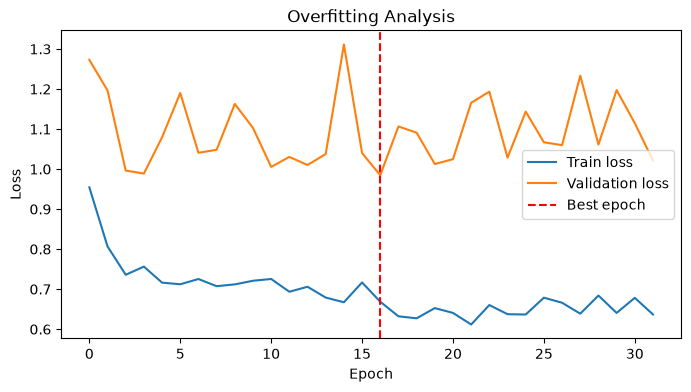

In [91]:

best_id = best["experiment_id"]
history = experiment_histories[best_id]

accuracy_gap = (
    best["train_accuracy"] - best["val_accuracy"]
)

print(f"Train-validation accuracy gap: {accuracy_gap:.3f}")

plt.figure(figsize=(8, 4))

plt.plot(history["train_loss"], label="Train loss")
plt.plot(history["val_loss"], label="Validation loss")

plt.axvline(
    best["best_epoch"] - 1,
    color="red",
    linestyle="--",
    label="Best epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Overfitting Analysis")
plt.legend()
plt.show()


In [92]:

# Predictions from the final selected MLP
best_model.eval()

with torch.no_grad():
    logits = best_model(X_test_t.to(DEVICE))
    predictions = logits.argmax(dim=1).cpu().numpy()

# Convert encoded labels to names
predicted_labels = np.asarray(class_names)[predictions]
true_labels = y_test.to_numpy()

# One row per test observation
errors_df = pd.DataFrame({
    "sample_group": groups_test.to_numpy(),
    "true_class": true_labels,
    "predicted_class": predicted_labels
})

assert len(errors_df) == len(X_test_t)
assert np.array_equal(
    np.asarray(class_names)[y_test_t.cpu().numpy()],
    true_labels
)

errors_df["is_error"] = (
    errors_df["true_class"] != errors_df["predicted_class"]
)

errors_df["error_type"] = np.where(
    errors_df["is_error"],
    errors_df["true_class"] + " -> " +
    errors_df["predicted_class"],
    "Correct"
)

display(errors_df.head())

print("Total errors:", errors_df["is_error"].sum())
print("Total observations:", len(errors_df))


,sample_group,true_class,predicted_class,is_error,error_type
0,sample_group_020,m0,m0,False,Correct
1,sample_group_020,m0,m0,False,Correct
2,sample_group_020,m0,m0,False,Correct
3,sample_group_020,m0,m0,False,Correct
4,sample_group_020,m0,m0,False,Correct


Total errors: 28
Total observations: 76


,n_samples,n_errors,error_rate
sample_group,,,
sample_group_056,3,3,1.000
sample_group_081,13,12,0.923
sample_group_012,4,3,0.750
sample_group_015,9,5,0.556
sample_group_035,3,1,0.333
sample_group_038,4,1,0.250
sample_group_076,5,1,0.200
sample_group_026,7,1,0.143
sample_group_020,12,1,0.083


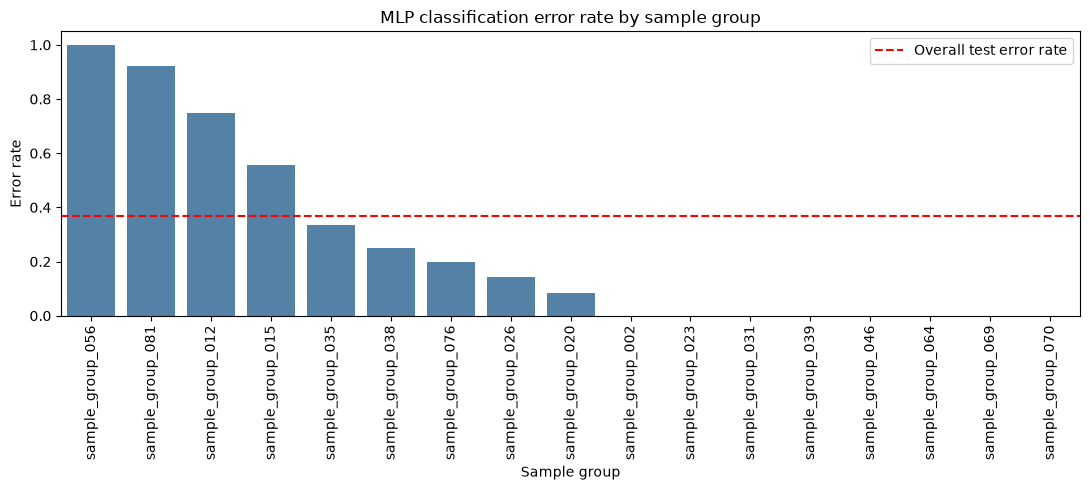

In [93]:

group_errors = (
    errors_df
    .groupby("sample_group")
    .agg(
        n_samples=("is_error", "size"),
        n_errors=("is_error", "sum"),
        error_rate=("is_error", "mean")
    )
    .sort_values(
        ["error_rate", "n_errors"],
        ascending=False
    )
)

display(group_errors.round(3))

plt.figure(figsize=(11, 5))

sns.barplot(
    data=group_errors.reset_index(),
    x="sample_group",
    y="error_rate",
    color="steelblue"
)

plt.axhline(
    errors_df["is_error"].mean(),
    linestyle="--",
    color="red",
    label="Overall test error rate"
)

plt.xticks(rotation=90)
plt.ylabel("Error rate")
plt.xlabel("Sample group")
plt.title("MLP classification error rate by sample group")
plt.legend()
plt.tight_layout()
plt.show()
